# Линейная регрессия для оценки стоимости домов в Эймсе

## 1. Введение

Цель работы — обучить линейные модели на реальных данных о продажах домов и выяснить, как регуляризация и метод главных компонент влияют на точность прогноза. Сравниваются обычная линейная регрессия (OLS), лассо (Lasso) и гребневая регрессия (Ridge). Для каждого метода оцениваются два варианта признаков с одинаковым разбиением наблюдений.

Для повторного запуска поместите приложенный `train.csv` рядом с ноутбуком, установите `numpy`, `pandas`, `matplotlib`, `scipy` и `scikit-learn` в среду Jupyter и выполните все ячейки сверху вниз. Результаты расчётов уже сохранены в ноутбуке.

## 2. Данные и первичный анализ

Источник — конкурс Kaggle *House Prices: Advanced Regression Techniques*. Наблюдения описывают продажи жилья в городе Эймс, штат Айова, в 2006–2010 годах. Целевая переменная `SalePrice` — цена сделки в долларах США. Для эксперимента заранее выбраны числовые признаки, описывающие размеры дома и участка, качество, возраст и оснащение. Категориальные переменные исключены из этого учебного эксперимента, чтобы сравнить PCA и исходное представление на одном компактном наборе.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titleweight": "bold",
})

data = pd.read_csv(Path("train.csv"))
target = "SalePrice"
labels = {
    "LotFrontage": "Длина фасада участка",
    "LotArea": "Площадь участка",
    "OverallQual": "Общее качество",
    "OverallCond": "Общее состояние",
    "YearBuilt": "Год постройки",
    "YearRemodAdd": "Год реконструкции",
    "TotalBsmtSF": "Площадь подвала",
    "1stFlrSF": "Площадь первого этажа",
    "2ndFlrSF": "Площадь второго этажа",
    "GrLivArea": "Жилая площадь над землёй",
    "FullBath": "Количество полных ванных",
    "BedroomAbvGr": "Количество спален над землёй",
    "TotRmsAbvGrd": "Количество комнат над землёй",
    "Fireplaces": "Количество каминов",
    "GarageCars": "Вместимость гаража",
    "GarageArea": "Площадь гаража",
    "WoodDeckSF": "Площадь деревянной террасы",
    "OpenPorchSF": "Площадь открытого крыльца",
    target: "Цена продажи, $",
}
features = list(labels)[:-1]
used = features + [target]
missing = data[used].isna().sum()

display(pd.DataFrame({
    "Показатель": [len(data), data.shape[1], data.shape[1] - 2,
                   data["Id"].duplicated().sum(), len(features)],
}, index=["Строки", "Столбцы", "Признаки без Id и SalePrice",
          "Повторяющиеся Id", "Выбранные признаки"]))
display(pd.DataFrame({"Описание": labels, "Пропуски": missing}))

,Показатель
Строки,1460
Столбцы,81
Признаки без Id и SalePrice,79
Повторяющиеся Id,0
Выбранные признаки,18


,Описание,Пропуски
LotFrontage,Длина фасада участка,259
LotArea,Площадь участка,0
OverallQual,Общее качество,0
OverallCond,Общее состояние,0
YearBuilt,Год постройки,0
YearRemodAdd,Год реконструкции,0
TotalBsmtSF,Площадь подвала,0
1stFlrSF,Площадь первого этажа,0
2ndFlrSF,Площадь второго этажа,0
GrLivArea,Жилая площадь над землёй,0


В `train.csv` 1460 размеченных сделок и 81 столбец. `Id` служит идентификатором, поэтому он исключён из признаков. Из 79 исходных характеристик в модели используются 18 числовых. Среди выбранных столбцов пропуски есть только в `LotFrontage` (259). В конкурсном `test.csv` нет фактических цен, поэтому контрольная выборка формируется из размеченных сделок.

## 3. Подготовка данных и распределения

,Строк
Удалено,259
После очистки,1201
Обучение,960
Контроль,241


,Минимум,Медиана,Максимум,Асимметрия
LotFrontage,21.0,70.0,313.0,2.43
LotArea,1300.0,9233.0,70761.0,4.65
OverallQual,1.0,6.0,10.0,0.20
OverallCond,2.0,5.0,9.0,0.71
YearBuilt,1872.0,1972.0,2010.0,-0.56
YearRemodAdd,1950.0,1995.0,2010.0,-0.52
TotalBsmtSF,0.0,990.0,6110.0,1.85
1stFlrSF,334.0,1080.0,4692.0,1.49
2ndFlrSF,0.0,0.0,2065.0,0.84
GrLivArea,334.0,1454.0,5642.0,1.59


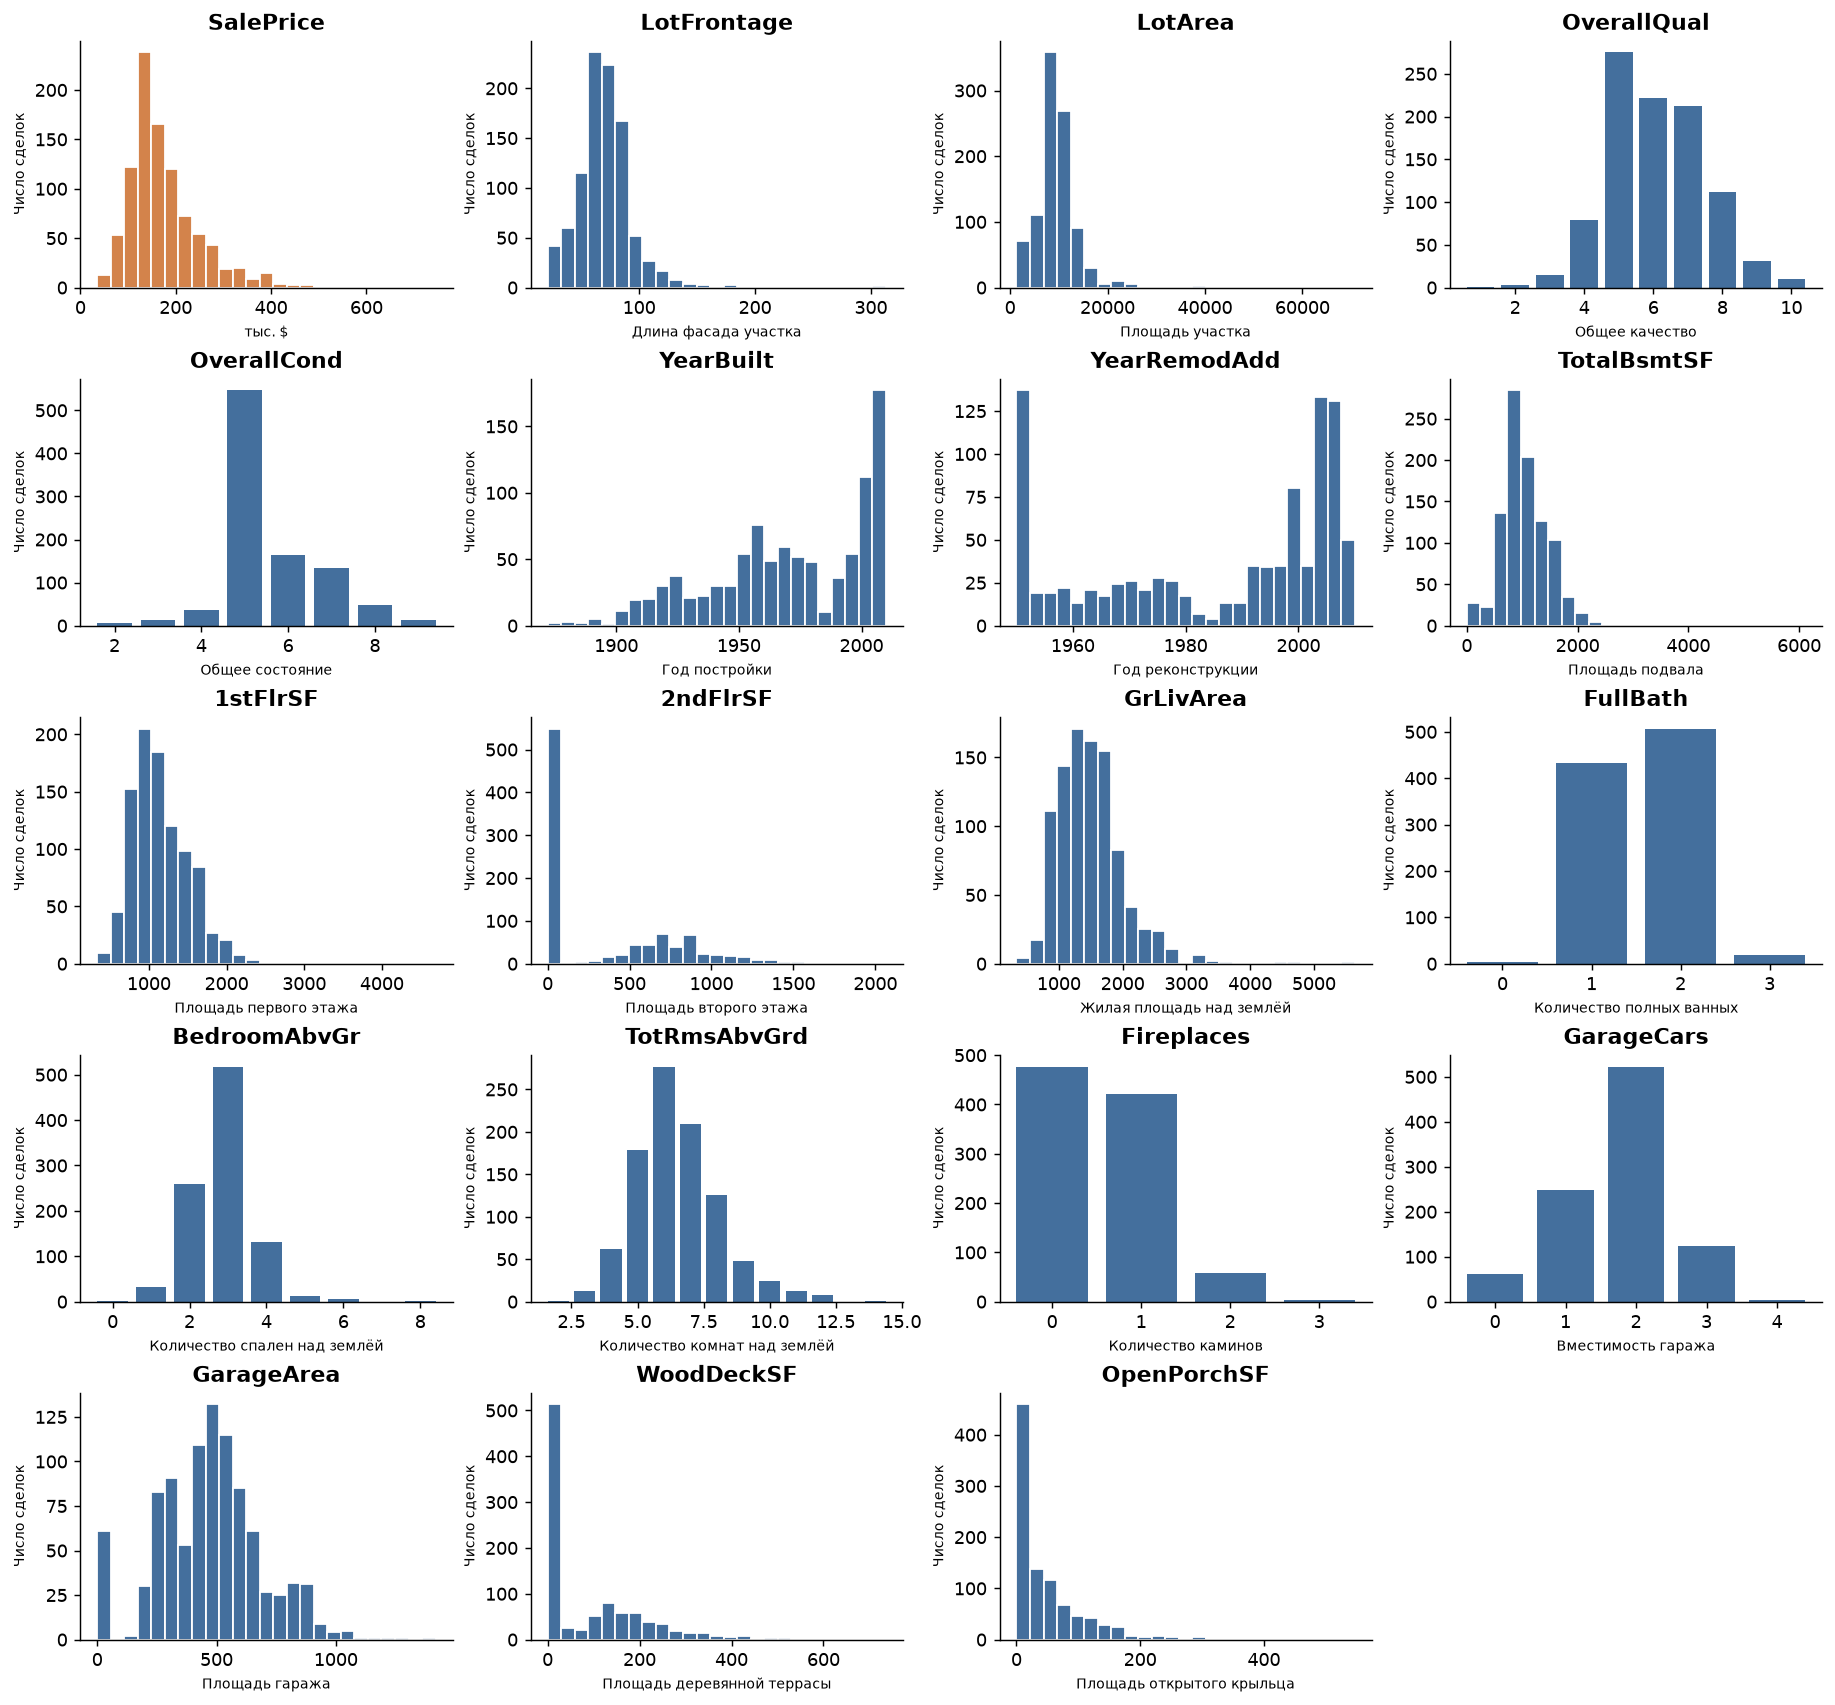

In [2]:
clean = data[used].dropna().copy()
X_train, X_test, y_train, y_test = train_test_split(
    clean[features], clean[target], test_size=0.20, random_state=42
)
train_data = X_train.assign(SalePrice=y_train)
summary = train_data.describe().T[["min", "50%", "max"]]
summary.columns = ["Минимум", "Медиана", "Максимум"]
summary["Асимметрия"] = train_data.skew()

display(pd.DataFrame(
    {"Строк": [len(data) - len(clean), len(clean), len(X_train), len(X_test)]},
    index=["Удалено", "После очистки", "Обучение", "Контроль"],
))
display(summary.round(2))

fig, axes = plt.subplots(5, 4, figsize=(14, 13), layout="constrained")
discrete = {"OverallQual", "OverallCond", "FullBath", "BedroomAbvGr",
            "TotRmsAbvGrd", "Fireplaces", "GarageCars"}
for ax, name in zip(axes.flat, [target] + features):
    values = train_data[name]
    if name in discrete:
        counts = values.value_counts().sort_index()
        ax.bar(counts.index, counts, color="#446f9d")
    else:
        ax.hist(values / (1000 if name == target else 1), bins=25,
                color="#d3834b" if name == target else "#446f9d", edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("тыс. $" if name == target else labels[name], fontsize=8)
    ax.set_ylabel("Число сделок", fontsize=8)
axes.flat[-1].set_visible(False)
plt.show()

Удалены 259 строк с пропусками в выбранных столбцах (17,7% исходного файла). Медианное или иное заполнение в этом эксперименте не применялось. Такой выбор сохраняет фактические значения фасада, но может ограничить применимость выводов к домам, для которых фасад указан. Площадь гаража и других элементов может равняться нулю: эти значения сохранены. Сделки с необычно высокой ценой также сохранены.

После очистки 960 сделок вошли в обучающую выборку и 241 — в контрольную (80/20 с округлением). Графики и статистики этого раздела относятся к обучающей части. Медианная цена составляет 157 000 $, асимметрия распределения равна 1,83, справа наблюдается хвост дорогих сделок. У `LotArea` тоже выраженный правый хвост (асимметрия 4,65). На графиках `2ndFlrSF`, `WoodDeckSF` и `OpenPorchSF` заметны пики около нуля, а `OverallQual` и `GarageCars` имеют дискретные шкалы.

В обоих вариантах эксперимента признаки стандартизируются до среднего 0 и стандартного отклонения 1 по данным обучения. Продажная цена используется в долларах без логарифмирования. Стандартизация выполняется внутри каждого конвейера и заново оценивается на обучающей части каждого разбиения кросс-валидации.

## 4. Моделирование и диагностика

### 4.1. Корреляционная матрица и VIF

Для парных связей используется коэффициент Пирсона. Для оценки совместной линейной зависимости каждый признак по очереди прогнозируется по остальным. Если коэффициент детерминации вспомогательной регрессии равен $R_j^2$, то $\mathrm{VIF}_j=1/(1-R_j^2)$. Превышение 5 используется как ориентир, а не как формальная проверка гипотезы.

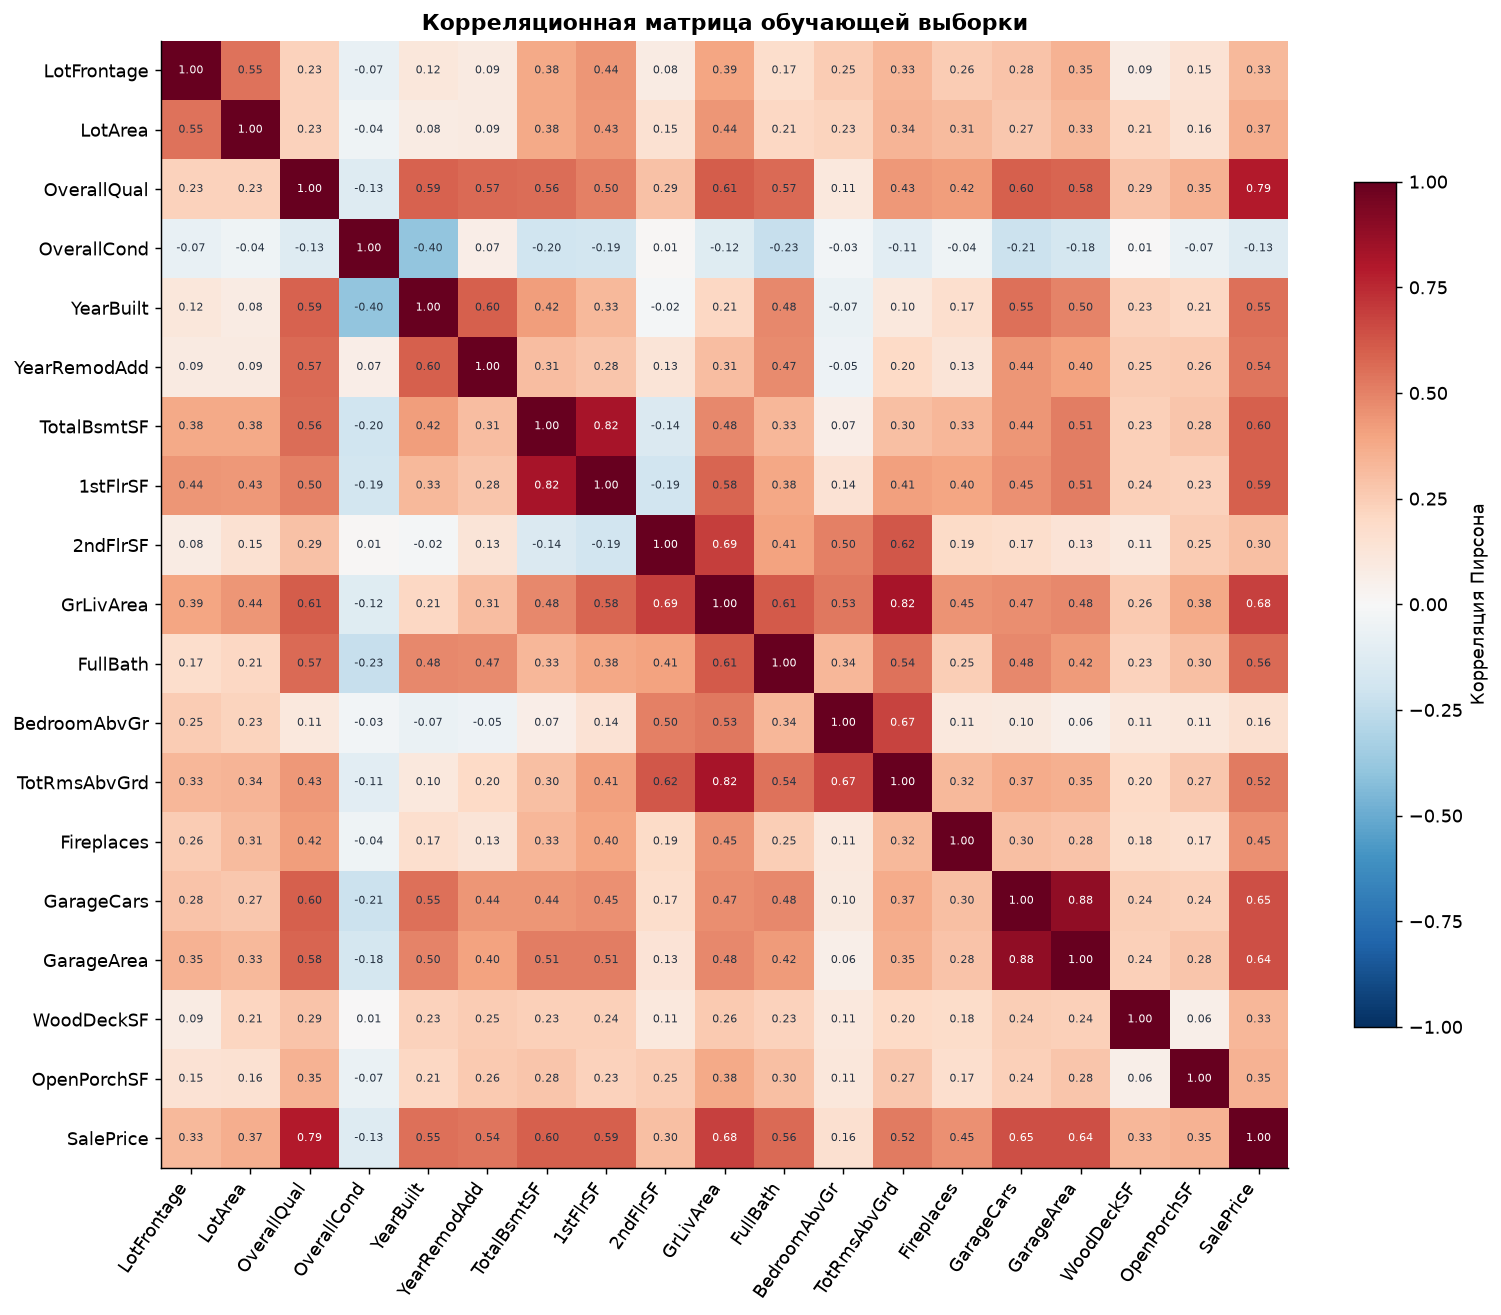

,VIF
GrLivArea,146.76
2ndFlrSF,99.49
1stFlrSF,82.25
GarageCars,5.39
GarageArea,5.36
TotRmsAbvGrd,4.30
TotalBsmtSF,3.78
YearBuilt,3.28
OverallQual,3.18
YearRemodAdd,2.35


In [3]:
def calculate_vif(frame):
    values = frame.to_numpy()
    result = {}
    for index, name in enumerate(frame.columns):
        predictors = np.delete(values, index, axis=1)
        response = values[:, index]
        auxiliary = LinearRegression().fit(predictors, response)
        unexplained = 1 - auxiliary.score(predictors, response)
        result[name] = np.inf if unexplained <= 1e-12 else 1 / unexplained
    return pd.Series(result, name="VIF").sort_values(ascending=False)


correlation = train_data.corr()
original_vif = calculate_vif(X_train)
fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
heatmap = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(used)), used, rotation=55, ha="right")
ax.set_yticks(range(len(used)), used)
for row in range(len(used)):
    for col in range(len(used)):
        value = correlation.iat[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=6.2,
                color="white" if abs(value) > 0.63 else "#263241")
fig.colorbar(heatmap, ax=ax, shrink=0.75, label="Корреляция Пирсона")
ax.set_title("Корреляционная матрица обучающей выборки")
plt.show()
display(original_vif.round(2).to_frame())

Среди показанных признаков сильную положительную связь с ценой имеют `OverallQual` ($r$ = 0,79) и `GrLivArea` ($r$ = 0,68). Вместимость и площадь гаража связаны между собой ($r$ = 0,88). VIF превышает 5 у 5 признаков. Максимум наблюдается у `GrLivArea` (VIF = 146,76). Это указывает на мультиколлинеарность: оценки отдельных коэффициентов OLS могут быть чувствительны к изменениям выборки, даже когда прогнозы достаточно точны.

### 4.2. Регрессия на исходных признаках

OLS минимизирует сумму квадратов остатков. Lasso добавляет штраф L1, который может обнулить некоторые коэффициенты. Ridge добавляет штраф L2, который уменьшает величину коэффициентов. Параметр $\alpha$ для каждой регуляризованной модели выбирается по среднему RMSE на пяти одинаковых разбиениях обучающей выборки (`KFold`, с перемешиванием и `random_state=42`).

RMSE измеряет типичный масштаб ошибки в долларах с повышенным весом крупных промахов. $R^2$ сравнивает сумму квадратов ошибок с разбросом цен относительно их среднего. MAPE — средняя абсолютная относительная ошибка, выраженная в процентах. Все фактические цены положительны.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}
specifications = {
    "OLS": (LinearRegression(), {}),
    "Lasso": (Lasso(max_iter=30000), {
        "model__alpha": [0.1, 1, 10, 30, 100, 300, 1000, 2000, 3000, 5000, 10000]
    }),
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 30, 100, 300, 1000]}),
}


def evaluate(use_pca=False):
    rows, predictions, fitted = {}, {}, {}
    for name, (estimator, grid) in specifications.items():
        steps = [("scale", StandardScaler())]
        if use_pca:
            steps.append(("pca", PCA(n_components=0.90, svd_solver="full")))
        steps.append(("model", estimator))
        search = GridSearchCV(
            Pipeline(steps), grid, scoring=scoring, refit="rmse", cv=cv, error_score="raise"
        )
        search.fit(X_train, y_train)
        predicted = search.predict(X_test)
        cv_result, best = search.cv_results_, search.best_index_
        rows[name] = {
            "α": search.best_params_.get("model__alpha", np.nan),
            "CV RMSE, $": -cv_result["mean_test_rmse"][best],
            "CV RMSE, σ": cv_result["std_test_rmse"][best],
            "CV R²": cv_result["mean_test_r2"][best],
            "CV MAPE, %": -100 * cv_result["mean_test_mape"][best],
            "Тест RMSE, $": np.sqrt(mean_squared_error(y_test, predicted)),
            "Тест R²": r2_score(y_test, predicted),
            "Тест MAPE, %": 100 * mean_absolute_percentage_error(y_test, predicted),
        }
        predictions[name] = predicted
        fitted[name] = search.best_estimator_
    return pd.DataFrame.from_dict(rows, orient="index"), predictions, fitted


def metric_table(frame):
    formats = {
        "α": "{:g}", "CV RMSE, $": "{:,.0f}", "CV RMSE, σ": "{:,.0f}",
        "CV R²": "{:.3f}", "CV MAPE, %": "{:.2f}", "Тест RMSE, $": "{:,.0f}",
        "Тест R²": "{:.3f}", "Тест MAPE, %": "{:.2f}",
    }
    return pd.DataFrame({
        name: frame[name].map(lambda value: pattern.format(value) if pd.notna(value) else "—")
        for name, pattern in formats.items()
    }, index=frame.index)


raw_scores, raw_predictions, raw_models = evaluate()
raw_best = raw_scores["Тест RMSE, $"].idxmin()
display(metric_table(raw_scores))

,α,"CV RMSE, $","CV RMSE, σ",CV R²,"CV MAPE, %","Тест RMSE, $",Тест R²,"Тест MAPE, %"
OLS,—,"42,319","7,610",0.715,14.92,"37,620",0.842,11.64
Lasso,3000,"41,755","5,327",0.726,14.63,"40,808",0.814,12.69
Ridge,300,"41,288","5,527",0.732,13.77,"40,481",0.817,11.94


На исходных признаках наименьший контрольный RMSE у **OLS**: 37 620 $, при $R^2$ = 0,842 и MAPE = 11,64%. Кросс-валидация выбрала $\alpha$ = 3 000,0 для Lasso и $\alpha$ = 300,0 для Ridge. В таблице $\sigma$ характеризует разброс RMSE между пяти блоками. Средние CV-метрики регуляризованных моделей рассчитаны на тех же разбиениях, которые использовались для настройки. Независимую итоговую оценку дают столбцы контрольной выборки.

### 4.3. Метод главных компонент

PCA строится на стандартизированных признаках. Число компонент заранее определяется правилом сохранения не менее 90% дисперсии признаков. Доля относится к разбросу входных данных, а не к объяснённой вариации цен. На графике каменистой осыпи показаны собственные значения, второй график показывает накопленную объяснённую дисперсию.

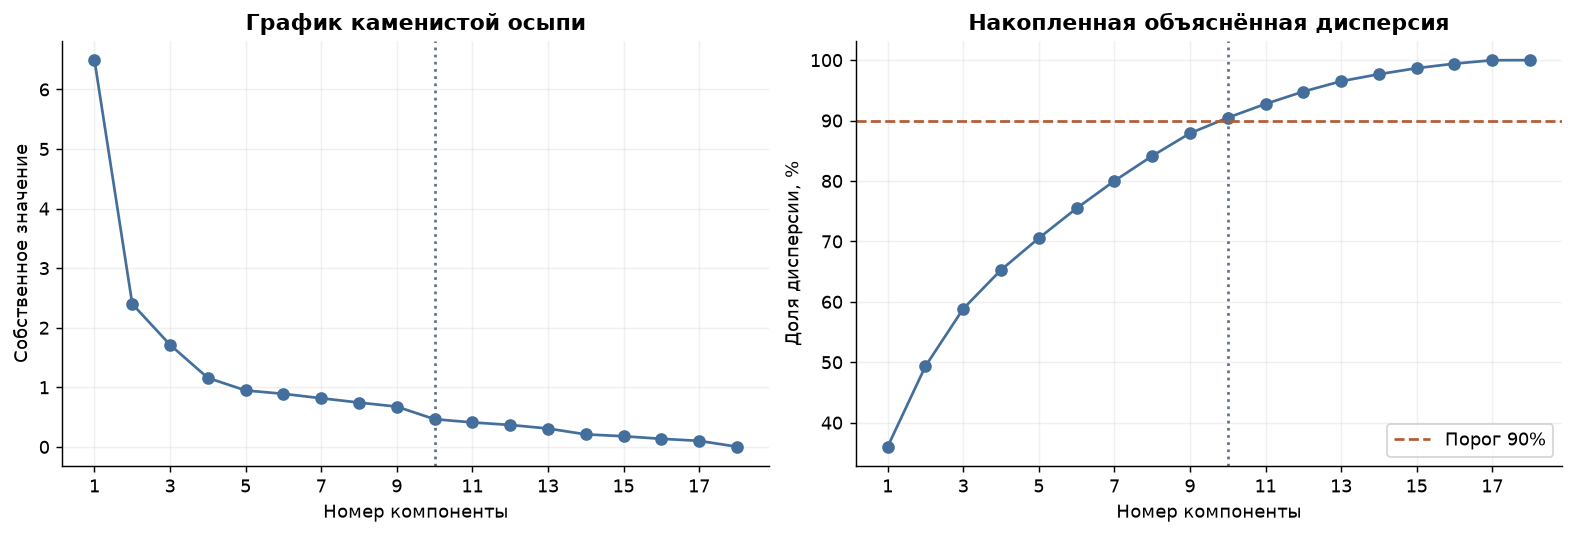

,Размерность,Максимальный VIF
Исходные признаки,18,146.7608
Главные компоненты,10,1.0000


In [5]:
scaled_train = StandardScaler().fit_transform(X_train)
full_pca = PCA(svd_solver="full").fit(scaled_train)
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
component_count = int(np.searchsorted(cumulative, 0.90, side="right") + 1)
component_numbers = np.arange(1, len(features) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(component_numbers, full_pca.explained_variance_, "o-", color="#446f9d")
axes[0].set(title="График каменистой осыпи", ylabel="Собственное значение")
axes[1].plot(component_numbers, 100 * cumulative, "o-", color="#446f9d")
axes[1].axhline(90, color="#b25c36", linestyle="--", label="Порог 90%")
axes[1].set(title="Накопленная объяснённая дисперсия", ylabel="Доля дисперсии, %")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.axvline(component_count, color="#617082", linestyle=":")
    ax.set(xlabel="Номер компоненты", xticks=component_numbers[::2])
    ax.grid(alpha=0.18)
plt.show()

train_components = pd.DataFrame(
    full_pca.transform(scaled_train)[:, :component_count],
    columns=[f"PC{i}" for i in range(1, component_count + 1)],
)
component_vif = calculate_vif(train_components)
max_component_corr = np.abs(train_components.corr().to_numpy() - np.eye(component_count)).max()
display(pd.DataFrame(
    {"Размерность": [len(features), component_count],
     "Максимальный VIF": [original_vif.max(), component_vif.max()]},
    index=["Исходные признаки", "Главные компоненты"],
).round(4))

Для порога 90% достаточно **10 из 18 компонент**. Они сохраняют 90,47% дисперсии обучающих признаков. Максимальная абсолютная корреляция между разными сохранёнными компонентами равна 5.1e-15, а максимальный VIF после преобразования равен 1,00. Следовательно, линейная зависимость между входными признаками устранена в пространстве сохранённых компонент на обучающей выборке. При кросс-валидации PCA строится заново в каждом обучающем блоке, поэтому точное число компонент в блоках может различаться.

### 4.4. Регрессия на компонентах и сравнение

In [6]:
pca_scores, pca_predictions, pca_models = evaluate(use_pca=True)
assert all(model.named_steps["pca"].n_components_ == component_count
           for model in pca_models.values())

all_scores = pd.concat({"Исходные": raw_scores, "PCA": pca_scores},
                       names=["Признаки", "Модель"])
test_columns = ["Тест RMSE, $", "Тест R²", "Тест MAPE, %"]
differences = pca_scores[test_columns] - raw_scores[test_columns]
best_group, best_model = all_scores["Тест RMSE, $"].idxmin()
best_mape_group, best_mape_model = all_scores["Тест MAPE, %"].idxmin()
best_cv_group, best_cv_model = all_scores["CV RMSE, $"].idxmin()
display(metric_table(all_scores))
display(differences.rename(columns={
    "Тест RMSE, $": "Δ RMSE, $", "Тест R²": "Δ R²", "Тест MAPE, %": "Δ MAPE, п.п.",
}).round({"Δ RMSE, $": 0, "Δ R²": 3, "Δ MAPE, п.п.": 2}))

α CV RMSE, $  ... Тест R² Тест MAPE, %
Признаки Модель                   ...                     
Исходные OLS        —     42,319  ...   0.842        11.64
         Lasso   3000     41,755  ...   0.814        12.69
         Ridge    300     41,288  ...   0.817        11.94
PCA      OLS        —     41,620  ...   0.819        12.53
         Lasso    0.1     41,620  ...   0.819        12.53
         Ridge    100     41,544  ...   0.813        12.46

[6 rows x 8 columns]

,"Δ RMSE, $",Δ R²,"Δ MAPE, п.п."
OLS,2628.0,-0.023,0.89
Lasso,-560.0,0.005,-0.16
Ridge,423.0,-0.004,0.52


Во второй таблице показана разность «PCA минус исходные признаки» для каждой модели. RMSE изменился на +2 628 $ у OLS, на -560 $ у Lasso и на +423 $ у Ridge. Лучший результат по контрольному RMSE у **OLS (исходные)**, по контрольному MAPE — у **OLS (исходные)**. По среднему RMSE кросс-валидации лидирует **Ridge (исходные)**. Различие между результатами кросс-валидации и контроля показывает, что порядок моделей зависит от набора оцениваемых сделок.

### 4.5. Остатки и постоянство дисперсии

Остаток определяется как фактическая цена минус прогноз. Сравниваются графики остатков с общей шкалой и горизонтальной линией на нуле. Дополнительно приведена среднеквадратичная величина остатков в нижней и верхней четвертях прогнозируемых цен. Для проверки зависимости разброса от прогноза используется вариант теста Бройша–Пагана по Кёнкеру: квадраты остатков регрессируются на прогноз со свободным членом. Статистика $nR^2$ сравнивается с распределением $\chi^2$ с одной степенью свободы. Это диагностическая проверка связи квадратов ошибок с уровнем прогноза на контрольной выборке.

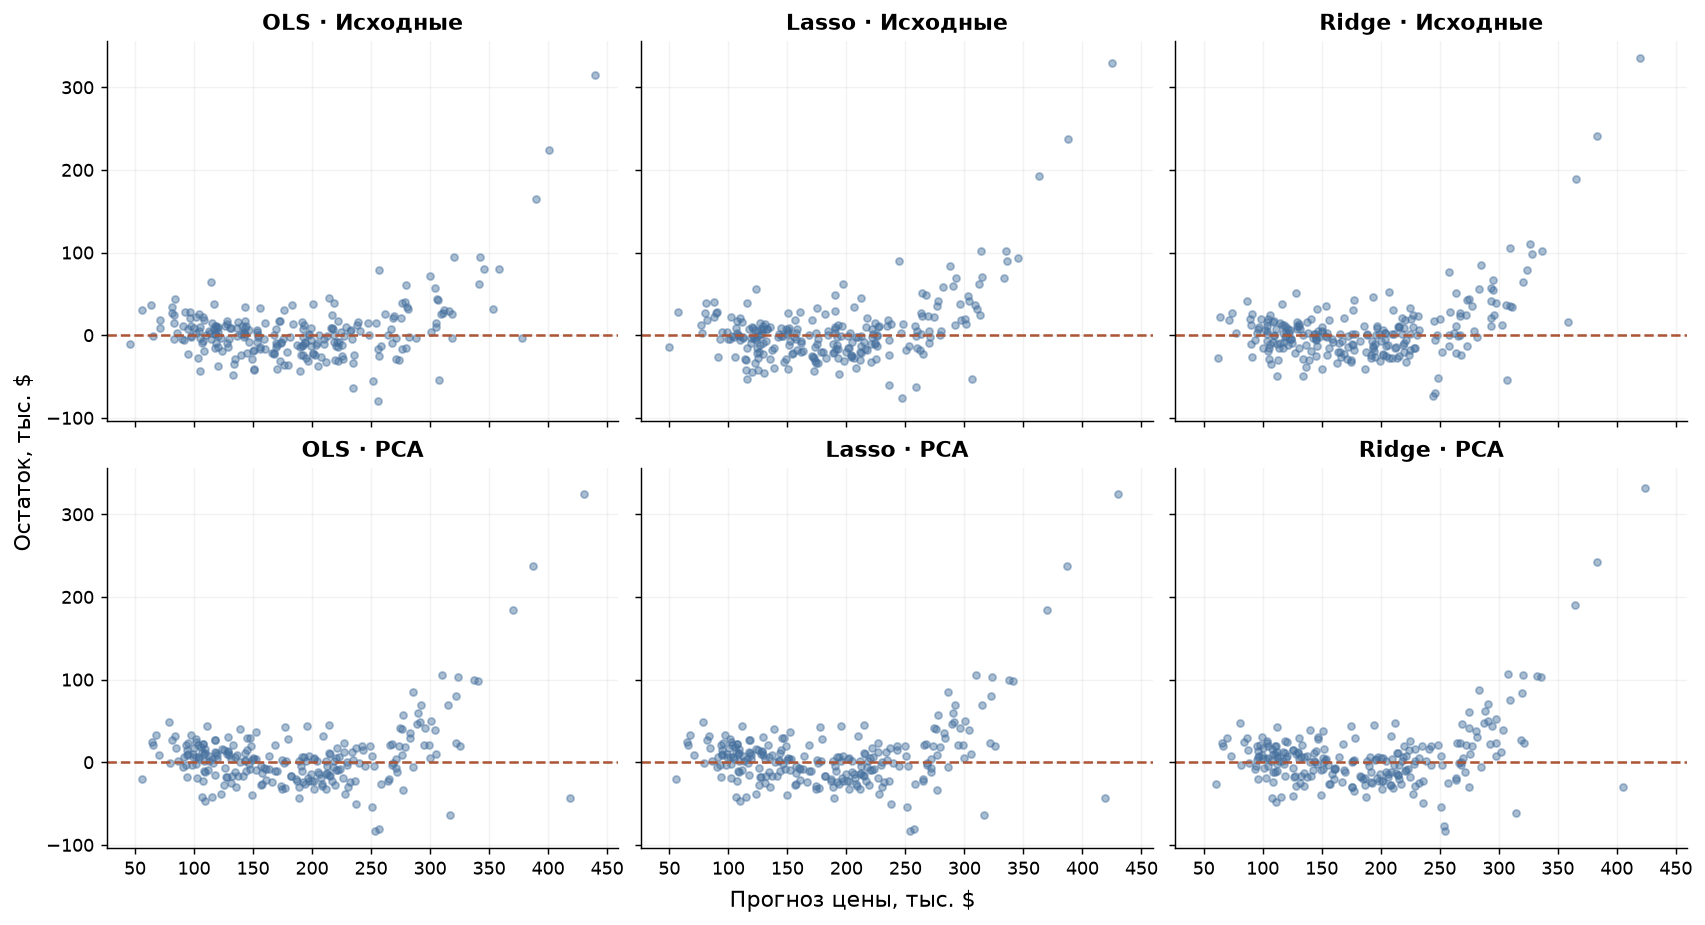

RMSE нижней четверти, $  ...         p
Признаки Модель                           ...          
Исходные OLS                   20138.858  ...  7.60e-09
         Lasso                 22069.124  ...  9.68e-10
         Ridge                 17477.573  ...  1.24e-09
PCA      OLS                   20542.207  ...  2.69e-09
         Lasso                 20542.123  ...  2.69e-09
         Ridge                 19890.888  ...  2.33e-09

[6 rows x 4 columns]

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True, layout="constrained")
diagnostics = {}
for row_axes, (group, predictions) in zip(
    axes, [("Исходные", raw_predictions), ("PCA", pca_predictions)]
):
    for ax, (name, predicted) in zip(row_axes, predictions.items()):
        residual = y_test.to_numpy() - predicted
        ax.scatter(predicted / 1000, residual / 1000, s=15, alpha=0.45, color="#446f9d")
        ax.axhline(0, color="#ac5537", linewidth=1.4, linestyle="--")
        ax.set_title(f"{name} · {group}")
        ax.grid(alpha=0.16)

        squared = residual**2
        auxiliary_X = predicted.reshape(-1, 1)
        auxiliary_r2 = LinearRegression().fit(auxiliary_X, squared).score(auxiliary_X, squared)
        lm_statistic = len(residual) * auxiliary_r2
        sorted_errors = squared[np.argsort(predicted)]
        quartile_size = len(residual) // 4
        diagnostics[group, name] = {
            "RMSE нижней четверти, $": np.sqrt(sorted_errors[:quartile_size].mean()),
            "RMSE верхней четверти, $": np.sqrt(sorted_errors[-quartile_size:].mean()),
            "LM": lm_statistic,
            "p": chi2.sf(lm_statistic, df=1),
        }
fig.supxlabel("Прогноз цены, тыс. $")
fig.supylabel("Остаток, тыс. $")
plt.show()
residual_table = pd.DataFrame.from_dict(diagnostics, orient="index")
residual_table.index.names = ["Признаки", "Модель"]
residual_display = residual_table.round(3)
residual_display["p"] = residual_table["p"].map("{:.2e}".format)
display(residual_display)

На графиках самые заметные остатки сосредоточены среди сделок с высокими прогнозными ценами. Для 6 из шести вариантов RMSE в верхней четверти выше, чем в нижней. У варианта с наименьшим общим RMSE эти величины составляют 66 877 и 20 139 $ соответственно.

При уровне значимости 0,05 тест обнаруживает признаки гетероскедастичности у 6 из шести моделей. Для варианта **OLS (исходные)** $p$ = 7.60e-09. Несколько крупных ошибок могут сильно влиять на квадрат остатков. Шесть проверок на одной выборке имеют разведочный характер, значения $p$ приведены без поправки на множественные сравнения.

## 5. Заключение

На общей контрольной выборке минимальный RMSE составил **37 620 $** у модели **OLS (исходные)**. Её $R^2$ составляет **0,842**, MAPE — **11,64%**.

PCA уменьшил число входов с 18 до 10, сохранив 90,47% дисперсии исходных признаков, и снизил максимальный VIF с 146,76 до 1,00. По минимальному тестовому RMSE среди трёх моделей исходное представление дало 37 620 $, а представление после PCA — 40 248 $. Сохранение дисперсии признаков и точность прогноза цены здесь оцениваются отдельно. Выводы относятся к выбранным характеристикам, сделкам с заполненным фасадом участка и одному случайному контрольному разбиению.

## 6. Список источников

*   Kaggle (Датасет): [House Prices - Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)
*   Pandas Documentation: [https://pandas.pydata.org/docs/](https://pandas.pydata.org/docs/)
*   Matplotlib Documentation: [https://matplotlib.org/stable/contents.html](https://matplotlib.org/stable/contents.html)
*   Seaborn Documentation: [https://seaborn.pydata.org/](https://seaborn.pydata.org/)
*   Scikit-learn Documentation: [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
*   Statsmodels Documentation: [https://www.statsmodels.org/stable/index.html](https://www.statsmodels.org/stable/index.html)

## 7. Приложение. Полный листинг кода

Код приведён в порядке выполнения ячеек.

```python
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titleweight": "bold",
})

data = pd.read_csv(Path("train.csv"))
target = "SalePrice"
labels = {
    "LotFrontage": "Длина фасада участка",
    "LotArea": "Площадь участка",
    "OverallQual": "Общее качество",
    "OverallCond": "Общее состояние",
    "YearBuilt": "Год постройки",
    "YearRemodAdd": "Год реконструкции",
    "TotalBsmtSF": "Площадь подвала",
    "1stFlrSF": "Площадь первого этажа",
    "2ndFlrSF": "Площадь второго этажа",
    "GrLivArea": "Жилая площадь над землёй",
    "FullBath": "Количество полных ванных",
    "BedroomAbvGr": "Количество спален над землёй",
    "TotRmsAbvGrd": "Количество комнат над землёй",
    "Fireplaces": "Количество каминов",
    "GarageCars": "Вместимость гаража",
    "GarageArea": "Площадь гаража",
    "WoodDeckSF": "Площадь деревянной террасы",
    "OpenPorchSF": "Площадь открытого крыльца",
    target: "Цена продажи, $",
}
features = list(labels)[:-1]
used = features + [target]
missing = data[used].isna().sum()

display(pd.DataFrame({
    "Показатель": [len(data), data.shape[1], data.shape[1] - 2,
                   data["Id"].duplicated().sum(), len(features)],
}, index=["Строки", "Столбцы", "Признаки без Id и SalePrice",
          "Повторяющиеся Id", "Выбранные признаки"]))
display(pd.DataFrame({"Описание": labels, "Пропуски": missing}))

clean = data[used].dropna().copy()
X_train, X_test, y_train, y_test = train_test_split(
    clean[features], clean[target], test_size=0.20, random_state=42
)
train_data = X_train.assign(SalePrice=y_train)
summary = train_data.describe().T[["min", "50%", "max"]]
summary.columns = ["Минимум", "Медиана", "Максимум"]
summary["Асимметрия"] = train_data.skew()

display(pd.DataFrame(
    {"Строк": [len(data) - len(clean), len(clean), len(X_train), len(X_test)]},
    index=["Удалено", "После очистки", "Обучение", "Контроль"],
))
display(summary.round(2))

fig, axes = plt.subplots(5, 4, figsize=(14, 13), layout="constrained")
discrete = {"OverallQual", "OverallCond", "FullBath", "BedroomAbvGr",
            "TotRmsAbvGrd", "Fireplaces", "GarageCars"}
for ax, name in zip(axes.flat, [target] + features):
    values = train_data[name]
    if name in discrete:
        counts = values.value_counts().sort_index()
        ax.bar(counts.index, counts, color="#446f9d")
    else:
        ax.hist(values / (1000 if name == target else 1), bins=25,
                color="#d3834b" if name == target else "#446f9d", edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("тыс. $" if name == target else labels[name], fontsize=8)
    ax.set_ylabel("Число сделок", fontsize=8)
axes.flat[-1].set_visible(False)
plt.show()

def calculate_vif(frame):
    values = frame.to_numpy()
    result = {}
    for index, name in enumerate(frame.columns):
        predictors = np.delete(values, index, axis=1)
        response = values[:, index]
        auxiliary = LinearRegression().fit(predictors, response)
        unexplained = 1 - auxiliary.score(predictors, response)
        result[name] = np.inf if unexplained <= 1e-12 else 1 / unexplained
    return pd.Series(result, name="VIF").sort_values(ascending=False)


correlation = train_data.corr()
original_vif = calculate_vif(X_train)
fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
heatmap = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(used)), used, rotation=55, ha="right")
ax.set_yticks(range(len(used)), used)
for row in range(len(used)):
    for col in range(len(used)):
        value = correlation.iat[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=6.2,
                color="white" if abs(value) > 0.63 else "#263241")
fig.colorbar(heatmap, ax=ax, shrink=0.75, label="Корреляция Пирсона")
ax.set_title("Корреляционная матрица обучающей выборки")
plt.show()
display(original_vif.round(2).to_frame())

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}
specifications = {
    "OLS": (LinearRegression(), {}),
    "Lasso": (Lasso(max_iter=30000), {
        "model__alpha": [0.1, 1, 10, 30, 100, 300, 1000, 2000, 3000, 5000, 10000]
    }),
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 30, 100, 300, 1000]}),
}


def evaluate(use_pca=False):
    rows, predictions, fitted = {}, {}, {}
    for name, (estimator, grid) in specifications.items():
        steps = [("scale", StandardScaler())]
        if use_pca:
            steps.append(("pca", PCA(n_components=0.90, svd_solver="full")))
        steps.append(("model", estimator))
        search = GridSearchCV(
            Pipeline(steps), grid, scoring=scoring, refit="rmse", cv=cv, error_score="raise"
        )
        search.fit(X_train, y_train)
        predicted = search.predict(X_test)
        cv_result, best = search.cv_results_, search.best_index_
        rows[name] = {
            "α": search.best_params_.get("model__alpha", np.nan),
            "CV RMSE, $": -cv_result["mean_test_rmse"][best],
            "CV RMSE, σ": cv_result["std_test_rmse"][best],
            "CV R²": cv_result["mean_test_r2"][best],
            "CV MAPE, %": -100 * cv_result["mean_test_mape"][best],
            "Тест RMSE, $": np.sqrt(mean_squared_error(y_test, predicted)),
            "Тест R²": r2_score(y_test, predicted),
            "Тест MAPE, %": 100 * mean_absolute_percentage_error(y_test, predicted),
        }
        predictions[name] = predicted
        fitted[name] = search.best_estimator_
    return pd.DataFrame.from_dict(rows, orient="index"), predictions, fitted


def metric_table(frame):
    formats = {
        "α": "{:g}", "CV RMSE, $": "{:,.0f}", "CV RMSE, σ": "{:,.0f}",
        "CV R²": "{:.3f}", "CV MAPE, %": "{:.2f}", "Тест RMSE, $": "{:,.0f}",
        "Тест R²": "{:.3f}", "Тест MAPE, %": "{:.2f}",
    }
    return pd.DataFrame({
        name: frame[name].map(lambda value: pattern.format(value) if pd.notna(value) else "—")
        for name, pattern in formats.items()
    }, index=frame.index)


raw_scores, raw_predictions, raw_models = evaluate()
raw_best = raw_scores["Тест RMSE, $"].idxmin()
display(metric_table(raw_scores))

scaled_train = StandardScaler().fit_transform(X_train)
full_pca = PCA(svd_solver="full").fit(scaled_train)
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
component_count = int(np.searchsorted(cumulative, 0.90, side="right") + 1)
component_numbers = np.arange(1, len(features) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(component_numbers, full_pca.explained_variance_, "o-", color="#446f9d")
axes[0].set(title="График каменистой осыпи", ylabel="Собственное значение")
axes[1].plot(component_numbers, 100 * cumulative, "o-", color="#446f9d")
axes[1].axhline(90, color="#b25c36", linestyle="--", label="Порог 90%")
axes[1].set(title="Накопленная объяснённая дисперсия", ylabel="Доля дисперсии, %")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.axvline(component_count, color="#617082", linestyle=":")
    ax.set(xlabel="Номер компоненты", xticks=component_numbers[::2])
    ax.grid(alpha=0.18)
plt.show()

train_components = pd.DataFrame(
    full_pca.transform(scaled_train)[:, :component_count],
    columns=[f"PC{i}" for i in range(1, component_count + 1)],
)
component_vif = calculate_vif(train_components)
max_component_corr = np.abs(train_components.corr().to_numpy() - np.eye(component_count)).max()
display(pd.DataFrame(
    {"Размерность": [len(features), component_count],
     "Максимальный VIF": [original_vif.max(), component_vif.max()]},
    index=["Исходные признаки", "Главные компоненты"],
).round(4))

pca_scores, pca_predictions, pca_models = evaluate(use_pca=True)
assert all(model.named_steps["pca"].n_components_ == component_count
           for model in pca_models.values())

all_scores = pd.concat({"Исходные": raw_scores, "PCA": pca_scores},
                       names=["Признаки", "Модель"])
test_columns = ["Тест RMSE, $", "Тест R²", "Тест MAPE, %"]
differences = pca_scores[test_columns] - raw_scores[test_columns]
best_group, best_model = all_scores["Тест RMSE, $"].idxmin()
best_mape_group, best_mape_model = all_scores["Тест MAPE, %"].idxmin()
best_cv_group, best_cv_model = all_scores["CV RMSE, $"].idxmin()
display(metric_table(all_scores))
display(differences.rename(columns={
    "Тест RMSE, $": "Δ RMSE, $", "Тест R²": "Δ R²", "Тест MAPE, %": "Δ MAPE, п.п.",
}).round({"Δ RMSE, $": 0, "Δ R²": 3, "Δ MAPE, п.п.": 2}))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True, layout="constrained")
diagnostics = {}
for row_axes, (group, predictions) in zip(
    axes, [("Исходные", raw_predictions), ("PCA", pca_predictions)]
):
    for ax, (name, predicted) in zip(row_axes, predictions.items()):
        residual = y_test.to_numpy() - predicted
        ax.scatter(predicted / 1000, residual / 1000, s=15, alpha=0.45, color="#446f9d")
        ax.axhline(0, color="#ac5537", linewidth=1.4, linestyle="--")
        ax.set_title(f"{name} · {group}")
        ax.grid(alpha=0.16)

        squared = residual**2
        auxiliary_X = predicted.reshape(-1, 1)
        auxiliary_r2 = LinearRegression().fit(auxiliary_X, squared).score(auxiliary_X, squared)
        lm_statistic = len(residual) * auxiliary_r2
        sorted_errors = squared[np.argsort(predicted)]
        quartile_size = len(residual) // 4
        diagnostics[group, name] = {
            "RMSE нижней четверти, $": np.sqrt(sorted_errors[:quartile_size].mean()),
            "RMSE верхней четверти, $": np.sqrt(sorted_errors[-quartile_size:].mean()),
            "LM": lm_statistic,
            "p": chi2.sf(lm_statistic, df=1),
        }
fig.supxlabel("Прогноз цены, тыс. $")
fig.supylabel("Остаток, тыс. $")
plt.show()
residual_table = pd.DataFrame.from_dict(diagnostics, orient="index")
residual_table.index.names = ["Признаки", "Модель"]
residual_display = residual_table.round(3)
residual_display["p"] = residual_table["p"].map("{:.2e}".format)
display(residual_display)
```